# 36 · Flow matching과 ODE 생성

📎 **이번 질문** · 잡음 점을 자료 분포까지 보내는 속도를, 이동 경로를 매번 풀지 않고 배울 수 있을까요?

준비물: 03·04의 tanh 미분과 Adam, 12 Gaussian, 27 샘플 평균, 30 flow와 33 연속 이동입니다. NumPy·CPU float64, 합성 자료만 쓰며 다른 노트북 실행 상태에 의존하지 않습니다.

| 표시 | 읽을 것 |
|---|---|
| 🔑 | 식·shape·학습 규약 |
| 🔍 | 그림·손계산·독립 평가 |
| 📎 | 용어·코드 설명 |
| ✏️ | 핵심 한두 줄과 검사 |

**반드시 가져갈 세 가지:** ① 조건부 직선 경로의 속도와 주변 속도를 구분합니다. ② 시간 조건부 속도장을 전체 미분하고 실제 학습합니다. ③ 학습 후 ODE를 풀 때 모델·적분·표본 오차를 따로 읽습니다.

[학습 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/flow_matching_plots.py)

In [1]:
# 준비 셀: 배열·그림·독립 중심차분 도구입니다.
import sys
from pathlib import Path
import numpy as np
project_root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient,rel_error
from src.utils.flow_matching_plots import (plot_straight_paths,plot_conditional_average,
    plot_velocity_network,plot_flow_data,plot_flow_learning,plot_ode_steps,
    plot_solver_error,plot_flow_samples,plot_flow_fields)
setup_plots()

'Arial Unicode MS'

## 🔑 1. 잡음 점과 자료 점을 직선으로 잇습니다

**이 절에서 가져갈 것:** 학습용 경로점과 그 미분은 endpoint 두 개만 있으면 계산됩니다.

잡음 위의 점 $x_0$를 과일 측정값 $x_1$까지 보낸다고 생각합니다. 먼저 독립적으로 뽑은 두 점을 직선으로 잇습니다. 이것은 생성기가 실제로 지나갈 경로를 미리 정하는 일이 아니라, 회귀 문제에 넣을 입력과 정답을 만드는 일입니다.

> **용어** · **endpoint**는 경로의 양 끝입니다. **velocity(속도)**는 시간에 대한 위치의 미분입니다. **조건부 경로**는 이번에 뽑은 두 endpoint가 주어졌을 때의 경로입니다. **coupling**은 두 endpoint를 함께 뽑는 결합 분포이며 여기서는 독립 곱분포입니다.

$$x_0\sim\mathcal N(0,I),\quad x_1\sim p_{data},\quad t\sim U[0,1],$$
$$x_t=(1-t)x_0+tx_1,\qquad u=x_1-x_0.$$

$x_0,x_1,x_t,u:(N,2)$, $t:(N,1)$입니다. 시간은 행마다 하나이며 두 좌표에 broadcast됩니다. t=0과1에서 각 endpoint로 돌아옵니다. 모든 쌍의 경로가 직선이어도, 학습한 하나의 주변 속도장이 만드는 생성 경로는 보통 곡선입니다.

> **코드** · `t[:,None]`은 시간 축을 열로 만듭니다. `stack(...,axis=0)`은 각 경로의 시간별 위치를 새로운 축에 모읍니다.

In [2]:
demo_x0=np.array([[-2.,-1.],[0.,2.],[2.,-1.]])
demo_x1=np.array([[1.5,0.],[-1.5,.3],[1.5,-.3]])
demo_t=np.linspace(0,1,5)
demo_paths=np.stack([(1-demo_t[:,None])*x0+demo_t[:,None]*x1 for x0,x1 in zip(demo_x0,demo_x1)])
demo_mid=.5*demo_x0+.5*demo_x1
demo_u=demo_x1-demo_x0

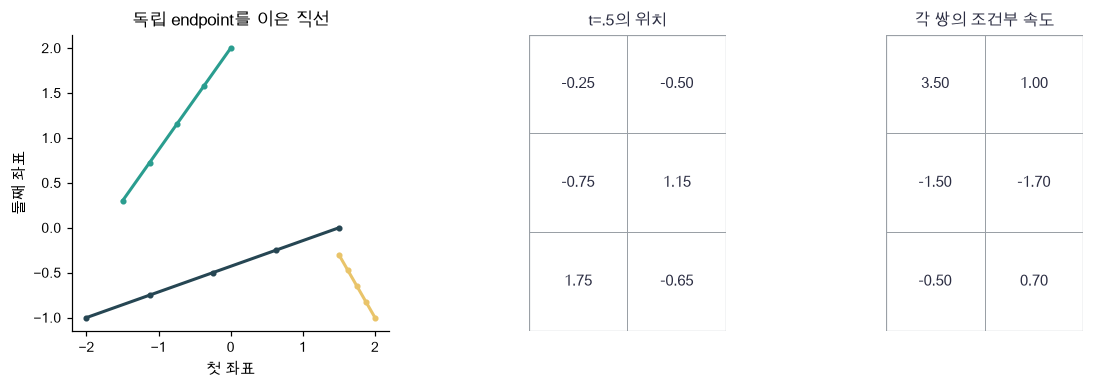

In [3]:
plot_straight_paths(demo_paths,demo_mid,demo_u)

🔍 **확인** · 시간 간격이 같으면 한 쌍의 위치 차이도 같습니다. 같은 중간 위치를 서로 다른 속도로 통과하는 쌍이 생길 수 있으므로, 그 위치만 보는 모델은 어느 쌍에서 왔는지 알 수 없습니다.

In [4]:
def straight_path(x0,x1,t):
    """독립 endpoint (N,2)와 시간 (N,1)의 선형 경로·조건부 속도입니다."""
    return (1-t)*x0+t*x1,x1-x0

In [5]:
loop_mid=np.zeros_like(demo_x0)
for i in range(len(demo_x0)):
    for d in range(2):
        loop_mid[i,d]=.5*demo_x0[i,d]+.5*demo_x1[i,d]
mid,u=straight_path(demo_x0,demo_x1,np.full((3,1),.5))
np.testing.assert_allclose(mid,loop_mid)  # 검산: 반복문과 벡터화의 축
np.testing.assert_allclose(mid[0],[-.25,-.5])  # 검산: 첫 점 손계산
np.testing.assert_allclose(straight_path(demo_x0,demo_x1,0.)[0],demo_x0)  # 검산: 시작
np.testing.assert_allclose(straight_path(demo_x0,demo_x1,1.)[0],demo_x1)  # 검산: 끝
dt=1e-5
numeric=(straight_path(demo_x0,demo_x1,.5+dt)[0]-straight_path(demo_x0,demo_x1,.5-dt)[0])/(2*dt)
np.testing.assert_allclose(numeric,u,atol=1e-10)  # 검산: 시간 중심차분 = 속도

### ✏️ 연습 1 · 직선의 위치와 속도

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

두 endpoint와 행별 시간으로 경로점과 속도를 반환하세요.

In [6]:
def exercise_path(x0,x1,t):
    """직선의 위치와 속도의 핵심 계산입니다."""
    ### 구현할 내용: 두 endpoint와 행별 시간으로 경로점과 속도를 반환하세요.
    raise NotImplementedError
    return xt,u

In [7]:
def check_path(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([[0.,2.]]),np.array([[4.,0.]]),.25),np.array([[[1.,1.5]],[[4.,-2.]]]))  # 검산: 좌표별 손계산
    print("연습 1 통과")

run_check(check_path,exercise_path,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_path: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
xt = (1-t)*x0+t*x1
u = x1-x0
```

</details>

## 🔑 2. 같은 위치의 여러 속도를 평균합니다

**이 절에서 가져갈 것:** 조건부 타깃을 회귀하면 그 위치·시간에서의 조건부 평균을 배웁니다.

같은 자리로 두 과일 경로가 들어오는데 속도가 (−1,1), (3,−1)이라고 해 봅시다. 모델은 위치와 시간만 받으므로 둘을 동시에 맞힐 수 없습니다. 제곱오차를 가장 작게 만드는 예측은 평균 (1,0)입니다.

> **용어** · **주변 경로 분포 $p_t$**는 endpoint 정보를 지우고 시간 t의 위치만 모은 분포입니다. **주변 속도**는 $v^*(x,t)=E[u\mid x_t=x,t]$입니다. **Flow matching**은 이 속도장을 회귀하는 학습 원리입니다. 조건부 타깃을 쓰는 목적을 CFM이라고 부릅니다.

$$L_{CFM}=E[\tfrac12\|v_\theta(x_t,t)-u\|^2],\quad
L_{FM}=E[\tfrac12\|v_\theta(x_t,t)-v^*(x_t,t)\|^2].$$
$$L_{CFM}=L_{FM}+E[\tfrac12\|u-v^*(x_t,t)\|^2].$$

교차항은 조건부 평균의 정의로0입니다. 마지막 항은 θ와 무관하므로 두 **기댓값 목적의 기울기**가 같습니다. 유한 미니배치의 두 손실이나 기울기가 매번 같다는 주장은 아닙니다. 정칙성·적분 가능성 아래 이 평균 속도는 $p_t$를 옮기는 연속 방정식의 속도가 됩니다. 여기서는 두 끝점 독립·선형 보간이라는 작은 구체화를 사용하며, 최적수송 coupling을 계산하지 않습니다.

In [8]:
conditional_targets=np.array([[-1.,1.],[3.,-1.]])
conditional_mean=conditional_targets.mean(axis=0)
trial_velocity=np.array([2.,2.])
cfm=.5*np.mean(np.sum((trial_velocity-conditional_targets)**2,axis=1))
fm=.5*np.sum((trial_velocity-conditional_mean)**2)
residual=.5*np.mean(np.sum((conditional_targets-conditional_mean)**2,axis=1))
decomposition=np.array([cfm,fm,residual])

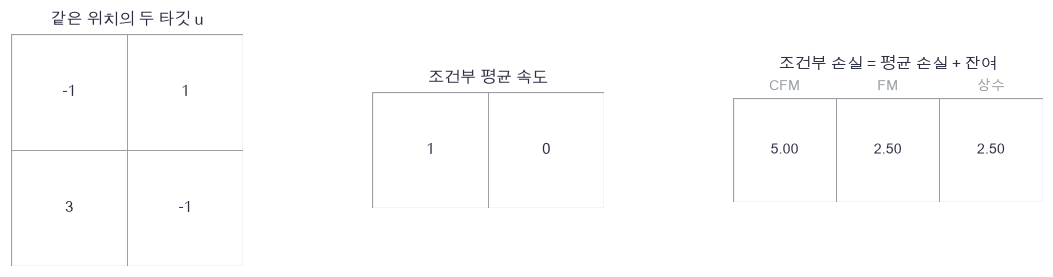

In [9]:
plot_conditional_average(conditional_targets,conditional_mean,decomposition)

🔍 **확인** · 손실은5=2.5+2.5로 분해됩니다. 평균 속도 (1,0)를 완벽히 맞혀도 두 타깃의 차이 때문에 CFM은0이 되지 않습니다. 학습 손실의 남은 값을 모두 모델 오차로 읽으면 안 됩니다.

In [10]:
def conditional_objective(prediction,targets):
    """같은 위치의 K개 조건부 타깃에 대한 평균 반 제곱거리와 예측 미분입니다."""
    difference=prediction-targets
    return .5*np.mean(np.sum(difference**2,axis=1)),difference.mean(axis=0)

In [11]:
loss,grad=conditional_objective(trial_velocity,conditional_targets)
np.testing.assert_allclose(loss,fm+residual)  # 검산: 정확한 유한 조건부 평균 분해
np.testing.assert_allclose(grad,trial_velocity-conditional_mean)  # 검산: 두 목적의 기울기
np.testing.assert_allclose(conditional_objective(conditional_mean,conditional_targets)[1],0.)  # 검산: 평균이 최소점
assert residual>0, '타깃이 달라 완벽한 평균 회귀에도 잔여 손실이 남아야 합니다'

### ✏️ 연습 2 · 주변 속도 타깃

같은 위치·시간을 지나는 K개 속도 (K,D)의 평균 (D,)을 구하세요.

In [12]:
def exercise_conditional_mean(U):
    """주변 속도 타깃의 핵심 계산입니다."""
    ### 구현할 내용: 같은 위치·시간을 지나는 K개 속도 (K,D)의 평균 (D,)을 구하세요.
    raise NotImplementedError
    return mean

In [13]:
def check_conditional_mean(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([[-1.,1.],[3.,-1.]])),[1.,0.])  # 검산: 조건부 두 경우 평균
    print("연습 2 통과")

run_check(check_conditional_mean,exercise_conditional_mean,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_conditional_mean: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
mean = U.mean(axis=0)
```

</details>

## 🔑 3. 시간까지 입력으로 받아 전체를 미분합니다

**이 절에서 가져갈 것:** 모델은 위치와 시간을 받고, 모든 가중치와 입력 경로를 직접 미분합니다.

같은 과일 좌표라도 잡음이 많은 시작과 자료에 가까운 끝에서 필요한 속도가 다릅니다. $A=[x_t,t]:(N,3)$으로 붙여 시간 조건을 줍니다.

> **용어** · **시간 조건부 속도장**은 $(x,t)$를 받아 위치의 이동 속도를 내는 함수입니다. **반 제곱거리**의 1/2는 미분의2를 없애는 규약이며 좌표는 합하고 관측은 평균합니다.

$$H=\tanh(AW+b):(N,F),\quad v=HV+c:(N,2),\quad
L=\frac1{2N}\sum_{i,d}(v_{id}-u_{id})^2.$$
$$G=(v-u)/N,\quad dV=H^TG,\quad dc=\sum_iG_i,$$
$$B=(GV^T)\odot(1-H^2),\quad dW=A^TB,\quad db=\sum_iB_i,\quad dA=BW^T.$$

$W:(3,F),b:(F,),V:(F,2),c:(2,)$입니다. 중심차분에서는 endpoint로 만든 u를 고정하고 x와 t를 각각 독립 연속 입력으로 봅니다. 경로의 t를 다시 바꾸면서 u까지 재추출하는 검사가 아닙니다.

> **코드** · `.T`는 이 2차원 표의 축을 바꿉니다. `sum(axis=0)`은 공유 bias의 모든 관측 기여를 더합니다. 사전의 배열을 `.copy()`하면 초기 모델을 보존할 수 있습니다.

In [14]:
network_inputs=np.array([[.2,-.4,.3],[-.1,.6,.7]])
network_hidden=np.tanh(network_inputs@np.array([[.2,-.1,.3],[-.2,.4,.1],[.1,.2,-.3]]))
network_prediction=network_hidden@np.array([[.3,-.2],[.1,.4],[-.2,.3]])
network_target=np.array([[1.,-.5],[-.2,.7]])
network_upstream=(network_prediction-network_target)/2

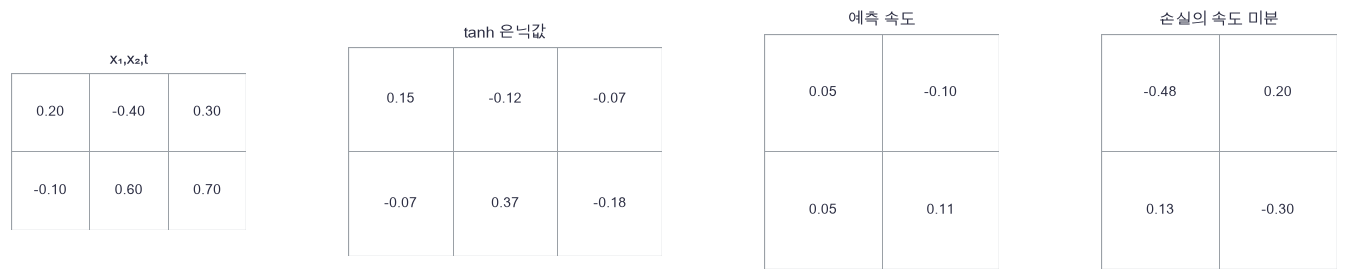

In [15]:
plot_velocity_network(network_inputs,network_hidden,network_prediction,network_upstream)

🔍 **확인** · 시간도 마지막 입력 열로 가중치와 곱해집니다. 학습할 때는 θ를 갱신하고, 입력 미분은 구현이 맞는지 확인하는 데 씁니다.

In [16]:
def init_velocity(seed=360,hidden=32):
    """시간을 붙인 3→H→2 tanh 속도장의 모든 파라미터입니다."""
    rng=np.random.default_rng(seed)
    return {'W':rng.normal(0,.3,(3,hidden)),'b':np.zeros(hidden),
            'V':rng.normal(0,.2,(hidden,2)),'c':np.zeros(2)}

In [17]:
def velocity_forward(x,t,p):
    """x:(N,2),t:(N,1) → v:(N,2). 시간은 입력의 마지막 열입니다."""
    inputs=np.concatenate([x,t],axis=1)
    hidden=np.tanh(inputs@p['W']+p['b'])
    return hidden@p['V']+p['c'],(inputs,hidden)

In [18]:
def velocity_loss(x,t,target,p):
    """좌표 합·관측 평균의 반 제곱거리와 모든 파라미터·연속 입력 미분입니다."""
    prediction,cache=velocity_forward(x,t,p)
    inputs,hidden=cache
    difference=prediction-target
    upstream=difference/len(x)
    pre=(upstream@p['V'].T)*(1-hidden**2)
    gradients={'V':hidden.T@upstream,'c':upstream.sum(axis=0),
               'W':inputs.T@pre,'b':pre.sum(axis=0)}
    return .5*np.mean(np.sum(difference**2,axis=1)),gradients,pre@p['W'].T

In [19]:
probe=init_velocity(369,hidden=3)
probe_x=np.array([[.2,-.5],[.7,.3],[-.2,.4]])
probe_t=np.array([[.2],[.6],[.9]])
probe_target=np.array([[1.,-.3],[-.5,.2],[.4,.7]])
_,analytic,analytic_inputs=velocity_loss(probe_x,probe_t,probe_target,probe)

In [20]:
def full_objective():
    """타깃은 고정하고 모든 파라미터·위치·시간을 검사하는 목적입니다."""
    return velocity_loss(probe_x,probe_t,probe_target,probe)[0]

In [21]:
errors=[]
for key in probe:
    numeric=numerical_gradient(full_objective,probe[key])
    np.testing.assert_allclose(analytic[key],numeric,atol=1e-8,rtol=2e-5)  # 검산: 모든 파라미터 원소
    errors.append(rel_error(analytic[key],numeric))
np.testing.assert_allclose(analytic_inputs[:,:2],numerical_gradient(full_objective,probe_x),atol=1e-8)  # 검산: 위치 입력
np.testing.assert_allclose(analytic_inputs[:,2:],numerical_gradient(full_objective,probe_t),atol=1e-8)  # 검산: 시간 입력
print('전체 파라미터 최대 상대오차',max(errors))

전체 파라미터 최대 상대오차 4.366981392836595e-10


### ✏️ 연습 3 · 좌표 합과 관측 평균

예측 V와 타깃 U:(N,D)의 손실과 V 미분을 구하세요.

In [22]:
def exercise_velocity_mse(V,U):
    """좌표 합과 관측 평균의 핵심 계산입니다."""
    ### 구현할 내용: 예측 V와 타깃 U:(N,D)의 손실과 V 미분을 구하세요.
    raise NotImplementedError
    return loss,grad

In [23]:
def check_velocity_mse(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    loss,g=candidate(np.array([[1.,2.],[3.,0.]]),np.zeros((2,2)))
    np.testing.assert_allclose(loss,3.5)  # 검산: (1+4+9)/4
    np.testing.assert_allclose(g,[[.5,1.],[1.5,0.]])  # 검산: 분모 N=2
    print("연습 3 통과")

run_check(check_velocity_mse,exercise_velocity_mse,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_velocity_mse: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
loss = .5*np.mean(np.sum((V-U)**2,axis=1))
grad = (V-U)/len(V)
```

</details>

## 🔑 4. 이동을 시뮬레이션하지 않고 실제 학습합니다

**이 절에서 가져갈 것:** 학습 중에는 ODE를 풀지 않고 선형 보간점의 속도 회귀만 합니다.

두 품종 과일의 측정값을 중심 (−1.5,0), (1.5,0), 표준편차 .35인 같은 비중 Gaussian으로 만듭니다. train2048(seed3601), valid512(3602), test512(3603)를 독립 생성합니다. 각 자료는2개 좌표입니다.

고정 계획: 3→32→2 tanh, 초기 seed360, 학습 seed3604, 배치64, Adam lr.003,1000갱신. train endpoint를 복원추출하고 매번 새 표준 Gaussian x0와 균등 t를 뽑습니다. valid의 x0·t는 seed3605로 고정해 경과만 기록하며 checkpoint를 고르지 않습니다. test는 마지막에만 평가하고 결과로 설정을 바꾸지 않습니다. 아래 소규모 실행은 한 seed의 예제입니다.

Adam은 $m=.9m+.1g$, $s=.999s+.001g^2$를 누적하고 편향 보정한 $\hat m,\hat s$로 $\theta\leftarrow\theta-.003\hat m/(\sqrt{\hat s}+10^{-8})$를 적용합니다. 구조는 MLP, 목적은 조건부 속도 회귀, optimizer는 Adam, 생성 절차는 다음 절 ODE로 각각 구분합니다.

> **코드** · `rng.integers(0,N,64)`는 train 번호의 복원추출입니다. `rng.normal(size=(64,2))`는 독립 출발점입니다. 사전의 `items()`는 파라미터 이름과 배열을 함께 순회합니다.

In [24]:
preview_rng=np.random.default_rng(3600)
source_preview=preview_rng.normal(size=(256,2))
preview_labels=preview_rng.integers(0,2,256)
target_preview=np.column_stack([3*preview_labels-1.5,np.zeros(256)])+.35*preview_rng.normal(size=(256,2))
training_plan=np.array([2048,512,512,1000])

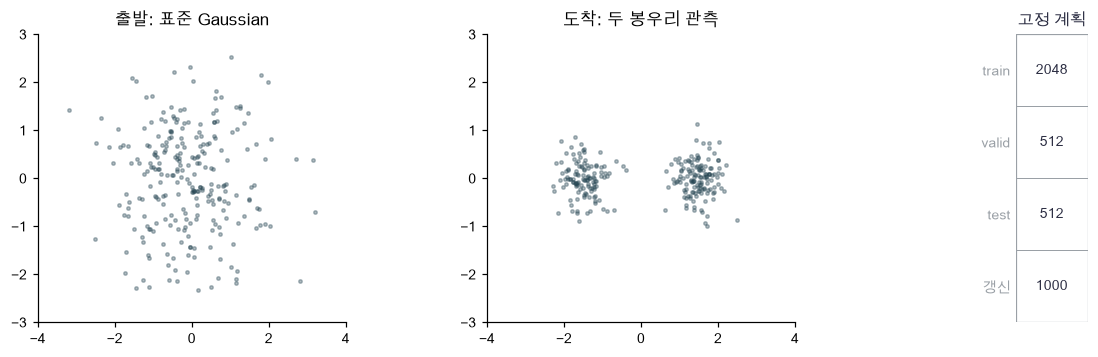

In [25]:
plot_flow_data(source_preview,target_preview,training_plan)

🔍 **확인** · 그림은 상황을 보는 예비256점이며 아래 학습 분할과 독립입니다. 학습 중 ODE를 풀지 않아도 되는 이유는 $x_t$와 u가 두 endpoint의 닫힌식이기 때문입니다.

In [26]:
def mixture_data(n,seed):
    """동일 확률의 두 2D Gaussian, 중심 (±1.5,0), 표준편차 .35입니다."""
    rng=np.random.default_rng(seed)
    centers=np.array([[-1.5,0.],[1.5,0.]])
    return centers[rng.integers(0,2,n)]+.35*rng.normal(size=(n,2))

In [27]:
def fixed_pairs(data,seed):
    """자료와 독립인 x0·t를 고정해 평가용 조건부 경로를 만듭니다."""
    # 쓰는 것: straight_path (1절)
    rng=np.random.default_rng(seed)
    x0=rng.normal(size=data.shape)
    t=rng.uniform(0,1,(len(data),1))
    xt,target=straight_path(x0,data,t)
    return xt,t,target

In [28]:
def adam_update(p,g,m,v,step,lr=.003):
    """두 모멘트와 편향 보정으로 속도장 파라미터를 갱신합니다."""
    for key in p:
        m[key]=.9*m[key]+.1*g[key]
        v[key]=.999*v[key]+.001*g[key]**2
        p[key]-=lr*(m[key]/(1-.9**step))/(np.sqrt(v[key]/(1-.999**step))+1e-8)

In [29]:
def train_velocity(data,validation,initial,steps=1000):
    """train endpoint만 64개씩 골라 새 x0·t로 1000회 학습합니다."""
    # 쓰는 것: straight_path (1절) · velocity_loss (3절)
    # 1. 초기 모델과 난수 계획을 보존합니다.
    p={key:value.copy() for key,value in initial.items()}
    m={key:np.zeros_like(value) for key,value in p.items()}
    v={key:np.zeros_like(value) for key,value in p.items()}
    rng=np.random.default_rng(3604)
    history=[[0,velocity_loss(*validation,p)[0]]]
    # 2. endpoint 쌍마다 시뮬레이션 없이 경로점과 속도를 계산합니다.
    for step in range(1,steps+1):
        x1=data[rng.integers(0,len(data),64)]
        x0=rng.normal(size=x1.shape)
        t=rng.uniform(0,1,(64,1))
        xt,target=straight_path(x0,x1,t)
        loss,gradients,_=velocity_loss(xt,t,target,p)
        adam_update(p,gradients,m,v,step)
        if step%100==0:
            history.append([step,velocity_loss(*validation,p)[0]])
    return p,np.array(history)

In [30]:
# 쓰는 것: init_velocity (3절) · mixture_data (4절)
train_data=mixture_data(2048,3601)
valid_data=mixture_data(512,3602)
test_data=mixture_data(512,3603)
valid_pairs=fixed_pairs(valid_data,3605)
initial=init_velocity()
fitted,history=train_velocity(train_data,valid_pairs,initial)
print('전체 파라미터 수',sum(value.size for value in fitted.values()))
print('같은 valid 쌍의 초기/최종 CFM',history[0,1],history[-1,1])
assert np.isfinite(history).all(), '모든 실행 손실이 유한해야 합니다'
np.testing.assert_array_equal(initial['W'],init_velocity()['W'])  # 검산: 초기 모델 불변

전체 파라미터 수 194
같은 valid 쌍의 초기/최종 CFM 2.71505181599219 1.4342237665823143


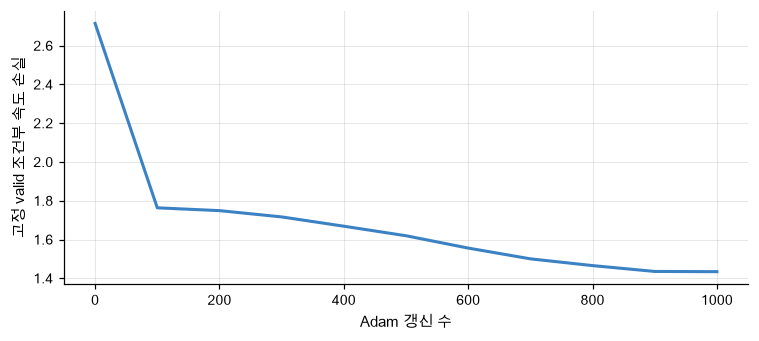

In [31]:
plot_flow_learning(history)

🔍 **확인** · 이 곡선은 고정 validation 쌍에 대한 CFM입니다. 조건부 타깃의 불확실성과 모델 오차를 모두 포함합니다. 작아졌다는 사실만으로 생성 분포의 정확성을 판정하지 않습니다.

### ✏️ 연습 4 · 평가용 경로 고정하기

고정 endpoint와 시간의 경로점을 계산하세요. 난수를 새로 뽑지 않습니다.

In [32]:
def exercise_fixed_validation(x0,x1,t):
    """평가용 경로 고정하기의 핵심 계산입니다."""
    ### 구현할 내용: 고정 endpoint와 시간의 경로점을 계산하세요. 난수를 새로 뽑지 않습니다.
    raise NotImplementedError
    return points

In [33]:
def check_fixed_validation(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([[0.,0.],[2.,0.]]),np.array([[2.,4.],[0.,2.]]),np.array([[.25],[.75]])),[[.5,1.],[.5,1.5]])  # 검산: 행마다 다른 시간
    print("연습 4 통과")

run_check(check_fixed_validation,exercise_fixed_validation,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_fixed_validation: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
points = (1-t)*x0+t*x1
```

</details>

## 🔑 5. 학습한 속도를 적분하고 오차를 나눕니다

**이 절에서 가져갈 것:** 생성은 새 x0를 고정한 뒤 ODE를 풉니다. 정답 endpoint는 사용하지 않습니다.

학습 후에는 $\dot x=v_\theta(x,t)$를0부터1까지 풉니다. 각 생성 샘플에 도착 자료를 다시 짝짓지 않습니다. Euler는 $x_{k+1}=x_k+h v(x_k,t_k)$이고, Heun은 $k_1=v(x_k,t_k)$, $k_2=v(x_k+hk_1,t_k+h)$를 평균해 $x_{k+1}=x_k+h(k_1+k_2)/2$입니다.

> **용어** · **ODE**는 위치의 시간 미분으로 이동을 정의하는 방정식입니다. **solver**는 이를 유한 스텝으로 근사하는 규칙입니다. **NFE**는 벡터장 함수를 평가한 횟수이며 여기서는 전체 배치를 평가한 호출 수입니다. Euler K스텝은K, Heun K스텝은2K입니다. **모델 오차**와 **적분 오차**는 다른 원인입니다.

먼저 $x'=x$, x(0)=1,h=.5의 한 스텝을 손으로 계산합니다. 그다음 알려진 Gaussian 속도장에서 적분만 검산하고, 마지막으로 학습한 속도장에서 같은 새 초기1024점을 Euler40·Heun20(NFE40)으로 보냅니다. NFE가 같다고 실제 시간·메모리가 같지는 않습니다.

In [34]:
step_size=.5
first_slope=1.
second_slope=1.+step_size*first_slope
one_step=np.array([[1.+step_size,1.+step_size*(first_slope+second_slope)/2,np.exp(step_size)]])
step_terms=np.array([[first_slope,second_slope,step_size*(first_slope+second_slope)/2]])

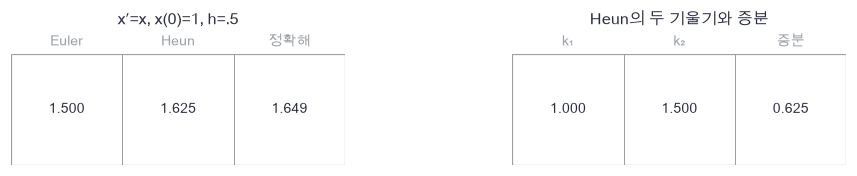

In [35]:
plot_ode_steps(one_step,step_terms)

🔍 **확인** · Euler1.5, Heun1.625, 정확해 약1.649입니다. 두 번 속도를 읽는 Heun이 이 예에서 더 가깝습니다. 항상 유리하다는 보장은 없으므로 다음은 정확한 다른 기준으로 확인합니다.

독립 $x_0\sim N(0,I), x_1\sim N(\mu,\operatorname{diag}(\sigma^2))$의 선형 경로에서 $s_t^2=(1-t)^2+t^2\sigma^2$입니다. Gaussian 조건부 평균으로
$$v^*(x,t)=\mu+\frac{t\sigma^2-(1-t)}{s_t^2}(x-t\mu).$$
이 ODE의 정확한 개별 경로는 $x(t)=t\mu+s_t x(0)$입니다. 미분하면 위 속도와 같고, t=1의 끝점은 $\mu+\sigma x(0)$입니다. 이는 학습용 독립 endpoint 쌍의 직선과는 다른 생성 경로입니다.

In [36]:
def gaussian_velocity(x,t,mean,scale):
    """독립 Gaussian endpoints 선형 경로의 정확한 주변 속도. scale은 좌표별 표준편차입니다."""
    variance=(1-t)**2+t**2*scale**2
    covariance=t*scale**2-(1-t)
    return mean+covariance/variance*(x-t*mean)

In [37]:
def integrate(field,initial,steps,method='euler'):
    """0→1의 고정 격자 Euler/Heun. 전체 경로와 실제 함수 평가 수를 반환합니다."""
    assert steps>0 and method in ['euler','heun'], '양의 스텝과 알려진 적분법이 필요합니다'
    x=initial.copy()
    path=[x.copy()]
    h=1/steps
    nfe=0
    for step in range(steps):
        t=step*h
        first=field(x,t)
        nfe+=1
        if method=='euler':
            x=x+h*first
        else:
            second=field(x+h*first,t+h)
            nfe+=1
            x=x+h*(first+second)/2
        path.append(x.copy())
    return np.array(path),nfe

In [38]:
def exponential_field(x,t):
    """solver 손계산용 x′=x입니다. t에 의존하지 않습니다."""
    return x

def oracle_field(x,t):
    """학습 오차가 없는 좌표별 Gaussian 수송 기준입니다."""
    return gaussian_velocity(x,t,np.array([1.,-.5]),np.array([.7,1.2]))

def learned_field(x,t):
    """학습한 모델에 같은 시간을 배치 열로 전달합니다."""
    # 쓰는 것: velocity_forward (3절) · fitted (4절)
    return velocity_forward(x,np.full((len(x),1),t),fitted)[0]

In [39]:
for method,expected in [('euler',2.),('heun',2.5)]:
    path,nfe=integrate(exponential_field,np.array([[1.]]),1,method)
    np.testing.assert_allclose(path[-1],expected)  # 검산: h=1 한 스텝 손계산
    assert nfe==1+(method=='heun'), '속도 평가 수를 실제 호출과 맞춰야 합니다'
oracle_start=np.random.default_rng(3608).normal(size=(64,2))
oracle_end=np.array([1.,-.5])+oracle_start*np.array([.7,1.2])
steps_grid=[4,8,16,32]
solver_errors=[]
solver_nfes=[]
for method in ['euler','heun']:
    rows=[integrate(oracle_field,oracle_start,steps,method) for steps in steps_grid]
    solver_errors.append([np.max(np.abs(path[-1]-oracle_end)) for path,nfe in rows])
    solver_nfes.append([nfe for path,nfe in rows])
print('정확장 Euler/Heun 끝점 오차',np.array(solver_errors))

정확장 Euler/Heun 끝점 오차 [[8.39693244e-01 4.47445949e-01 2.31900894e-01 1.18183546e-01]
 [4.76729396e-02 8.30870106e-03 1.58636873e-03 3.35603125e-04]]


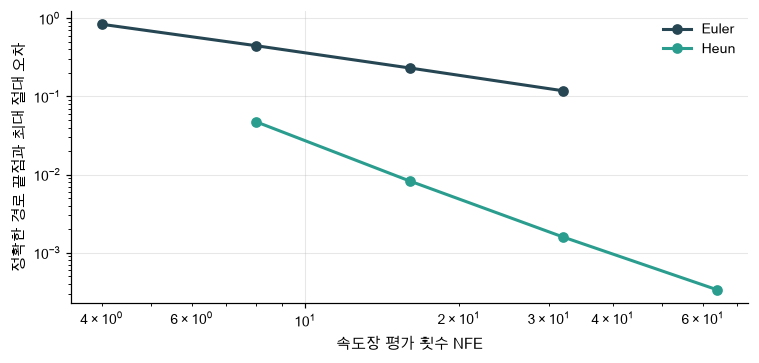

In [40]:
plot_solver_error(solver_nfes,solver_errors,["Euler","Heun"])

🔍 **확인** · 이 그림은 정확한 벡터장을 넣었으므로 오차 원인이 solver입니다. 실제 모델에서는 스텝을 늘려도 잘못 배운 속도 자체가 정답으로 바뀌지 않습니다.

이번 두 봉우리 자료는 기준 주변 속도도 계산할 수 있습니다. 성분 k마다 평균 $\mu_k$, 분산 $s_t^2=(1-t)^2+t^2(.35)^2$이고 $w_k(x,t)\propto\exp(-\|x-t\mu_k\|^2/(2s_t^2))$입니다. 같은 혼합 비중이라 $v^*=\sum_k w_k[\mu_k+\{t(.35)^2-(1-t)\}(x-t\mu_k)/s_t^2]$입니다. 이 기준은 평가에만 쓰며 학습 타깃은 계속 endpoint 차이입니다. 구현의 시간 입력은 (N,1)입니다.

In [41]:
def mixture_velocity(x,t):
    """학습과 별개인 정답 두 Gaussian 혼합의 조건부 평균 속도입니다."""
    means=np.array([[-1.5,0.],[1.5,0.]])
    variance=(1-t)**2+t**2*.35**2
    centered=x[:,None,:]-t[:,None,:]*means[None,:,:]
    score=-np.sum(centered**2,axis=2)/(2*variance)
    weight=np.exp(score-score.max(axis=1,keepdims=True))
    weight/=weight.sum(axis=1,keepdims=True)
    component=means[None,:,:]+(t*.35**2-(1-t))[:,None,:]/variance[:,None,:]*centered
    return np.sum(weight[:,:,None]*component,axis=1)

In [42]:
# 쓰는 것: fixed_pairs (4절) · test_data (4절) · velocity_loss (3절) · fitted (4절) · velocity_forward (3절)
test_pairs=fixed_pairs(test_data,3606)
test_points,test_times,test_target=test_pairs
exact_velocity=mixture_velocity(test_points,test_times)
predicted_velocity=velocity_forward(test_points,test_times,fitted)[0]
field_error=.5*np.mean(np.sum((predicted_velocity-exact_velocity)**2,axis=1))
print('test CFM / 정답 주변장 반 제곱오차',velocity_loss(*test_pairs,fitted)[0],field_error)
np.testing.assert_allclose(mixture_velocity(test_points,np.zeros((len(test_points),1))),-test_points,atol=1e-12)  # 검산: t=0, 자료 평균0
np.testing.assert_allclose(mixture_velocity(test_points,np.ones((len(test_points),1))),test_points,atol=1e-12)  # 검산: t=1, 독립 출발점 평균0

test CFM / 정답 주변장 반 제곱오차 1.325702583092808 0.11386617107224616


In [43]:
# 쓰는 것: velocity_forward (3절) · fitted (4절)
grid_x,grid_y=np.meshgrid(np.linspace(-2.5,2.5,13),np.linspace(-1.5,1.5,9))
grid_points=np.column_stack([grid_x.ravel(),grid_y.ravel()])
grid_t=np.full((len(grid_points),1),.5)
grid_exact=mixture_velocity(grid_points,grid_t)
grid_learned=velocity_forward(grid_points,grid_t,fitted)[0]

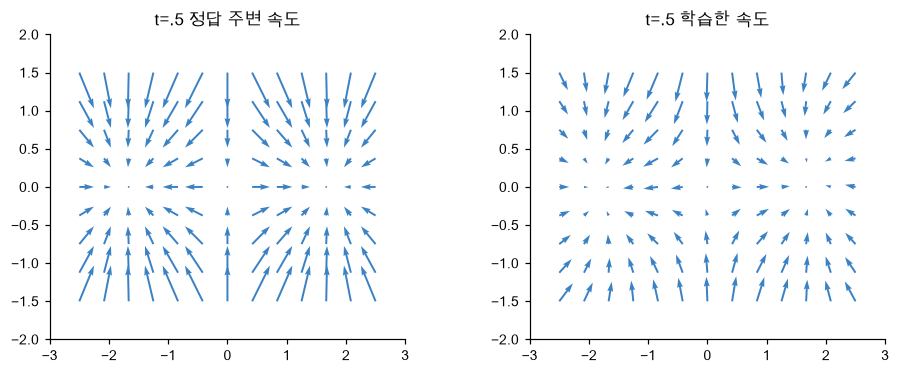

In [44]:
plot_flow_fields(grid_points,[grid_exact,grid_learned],["t=.5 정답 주변 속도","t=.5 학습한 속도"])

In [45]:
# 쓰는 것: test_data (4절) · integrate (5절) · learned_field (5절)
generation_start=np.random.default_rng(3607).normal(size=(1024,2))
euler_path,euler_nfe=integrate(learned_field,generation_start,40,'euler')
heun_path,heun_nfe=integrate(learned_field,generation_start,20,'heun')
assert euler_nfe==heun_nfe==40, '같은 NFE40을 비교해야 합니다'
np.testing.assert_array_equal(euler_path[0],heun_path[0])  # 검산: 같은 초기 잡음
for label,samples in [('test',test_data),('Euler',euler_path[-1]),('Heun',heun_path[-1])]:
    print(label,'평균',samples.mean(axis=0),'분산',samples.var(axis=0),'오른쪽 비율',np.mean(samples[:,0]>0))
    assert np.isfinite(samples).all(), '생성 결과와 평가 샘플은 유한해야 합니다'
print('두 solver 끝점의 짝지은 평균 거리',np.linalg.norm(euler_path[-1]-heun_path[-1],axis=1).mean())

test 평균 [ 0.12556802 -0.01147713] 분산 [2.30181283 0.11297809] 오른쪽 비율 0.541015625
Euler 평균 [-0.09077226 -0.02055846] 분산 [2.36061593 0.11677173] 오른쪽 비율 0.4833984375
Heun 평균 [-0.09093188 -0.02039894] 분산 [2.42115361 0.12158154] 오른쪽 비율 0.482421875
두 solver 끝점의 짝지은 평균 거리 0.023646898661433227


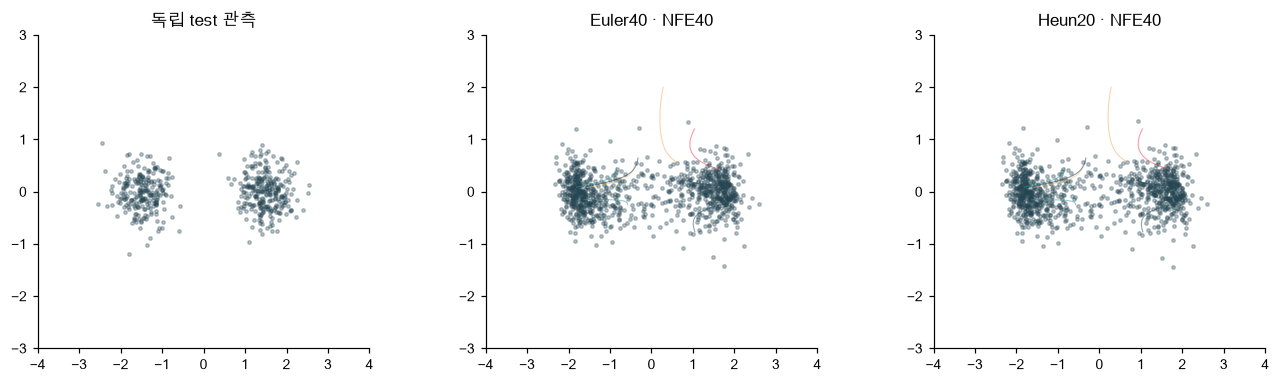

In [46]:
plot_flow_samples([test_data,euler_path[-1],heun_path[-1]],["독립 test 관측","Euler40 · NFE40","Heun20 · NFE40"],[None,euler_path[:,:8],heun_path[:,:8]])

🔍 **확인** · 선은 같은 초기점8개의 경로이며 점은 생성1024개 전부입니다. 정답 분포의 평균은(0,0), 분산은(2.3725,.1225), 오른쪽 비율은.5입니다. 표본 통계에는 샘플 오차가 있고, 평균·분산 일치만으로 분포가 같다고 결론 내릴 수 없습니다. 이 작은 모델의 근사 오차와 solver 간 차이를 함께 기록합니다. 우도나 log-Jacobian을 계산하지 않았으므로 30번처럼 밀도 평가를 했다고 부르지 않습니다.

### ✏️ 연습 5 · 두 속도를 평균한 Heun 갱신

이미 계산한 k1,k2와 h로 다음 위치를 반환하세요.

In [47]:
def exercise_heun(x,k1,k2,h):
    """두 속도를 평균한 Heun 갱신의 핵심 계산입니다."""
    ### 구현할 내용: 이미 계산한 k1,k2와 h로 다음 위치를 반환하세요.
    raise NotImplementedError
    return updated

In [48]:
def check_heun(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([1.]),np.array([1.]),np.array([1.5]),.5),[1.625])  # 검산: x′=x의 h=.5
    print("연습 5 통과")

run_check(check_heun,exercise_heun,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_heun: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
updated = x+h*(k1+k2)/2
```

</details>

## ✏️ 전체 연결 연습 A–D

목적·시간 조건·비용·짝지은 비교를 각각 바꿔 검산합니다.

### ✏️ 연습 A · 분모를 확인하기

두 목적의 차이에서 θ와 무관한 잔여 반 제곱거리를 계산하세요.

In [49]:
def exercise_residual(U,mean):
    """분모를 확인하기의 핵심 계산입니다."""
    ### 구현할 내용: 두 목적의 차이에서 θ와 무관한 잔여 반 제곱거리를 계산하세요.
    raise NotImplementedError
    return constant

In [50]:
def check_residual(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([[-1.,1.],[3.,-1.]]),np.array([1.,0.])),2.5)  # 검산: 조건부 분산
    print("연습 A 통과")

run_check(check_residual,exercise_residual,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_residual: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
constant = .5*np.mean(np.sum((U-mean)**2,axis=1))
```

</details>

### ✏️ 연습 B · 시간 열 붙이기

X:(N,2)와 T:(N,1)을 합쳐 입력(N,3)을 만드세요.

In [51]:
def exercise_time_column(X,T):
    """시간 열 붙이기의 핵심 계산입니다."""
    ### 구현할 내용: X:(N,2)와 T:(N,1)을 합쳐 입력(N,3)을 만드세요.
    raise NotImplementedError
    return A

In [52]:
def check_time_column(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.,2.],[3.,4.]]),np.array([[.2],[.8]])),[[1.,2.,.2],[3.,4.,.8]])  # 검산: 시간은 마지막 열
    print("연습 B 통과")

run_check(check_time_column,exercise_time_column,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_time_column: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
A = np.concatenate([X,T],axis=1)
```

</details>

### ✏️ 연습 C · 동일 평가 비용

정수 budget을 모두 쓸 때 Euler·Heun 스텝 수를 반환하세요. budget은 양의 짝수입니다.

In [53]:
def exercise_nfe_budget(budget):
    """동일 평가 비용의 핵심 계산입니다."""
    ### 구현할 내용: 정수 budget을 모두 쓸 때 Euler·Heun 스텝 수를 반환하세요. budget은 양의 짝수입니다.
    raise NotImplementedError
    return euler_steps,heun_steps

In [54]:
def check_nfe_budget(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    assert candidate(40)==(40,20), 'Heun은 한 스텝당 두 평가입니다'
    print("연습 C 통과")

run_check(check_nfe_budget,exercise_nfe_budget,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_nfe_budget: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
euler_steps,heun_steps = budget,budget//2
```

</details>

### ✏️ 연습 D · 같은 초기점의 끝점 비교

동일 초기점 순서의 두 끝점 X,Y:(N,D)에서 평균 Euclidean 거리를 구하세요.

In [55]:
def exercise_paired_endpoints(X,Y):
    """같은 초기점의 끝점 비교의 핵심 계산입니다."""
    ### 구현할 내용: 동일 초기점 순서의 두 끝점 X,Y:(N,D)에서 평균 Euclidean 거리를 구하세요.
    raise NotImplementedError
    return distance

In [56]:
def check_paired_endpoints(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([[3.,4.],[0.,0.]]),np.zeros((2,2))),2.5)  # 검산: 두 거리5와0 평균
    print("연습 D 통과")

run_check(check_paired_endpoints,exercise_paired_endpoints,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_paired_endpoints: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
distance = np.sqrt(np.sum((X-Y)**2,axis=1)).mean()
```

</details>

📎 **준비도: 네 가지를 각각 확인하세요**

- **설명:** 학습용 직선과 생성 ODE 경로가 달라도 되는 이유를 설명할 수 있나요?
- **수식:** CFM과 FM의 차이가 θ에 무관한 항임을 조건부 평균으로 유도할 수 있나요?
- **구현:** 시간 조건·전체 backward·Adam·Euler/Heun을 빈 셀부터 다시 쓸 수 있나요?
- **변형 검산:** 자료 분산이나 NFE를 바꿨을 때 조건부 불확실성·모델 오차·적분 오차를 나누어 비교할 수 있나요?

**원자료와 범위:** [Flow Matching for Generative Modeling](https://arxiv.org/abs/2210.02747)의 확률 경로·조건부 회귀·ODE 연결을 축소해 구현했습니다. 이 노트북은 독립 Gaussian 출발점과 자료 endpoint를 잇는 선형 경로 예제이며, 원논문의 대규모 네트워크·이미지 성능이나 최적수송 coupling을 재현한 것이 아닙니다. 분포 평가를 넓히려면 [37 생성 평가](37_generative_evaluation.ipynb)를 연결하세요.